# Four Transmon VQE with Optimizer and Noise Comparisons

Follow the four implementation steps in VQE_Coupled_Transmon.ipynb and Section 3 of the original vqe.ipynb. Coursework_1.ipynb supplies the commenting style.

| Procedure | Implementation |
|---|---|
| 3.1 Step 1 | Build and Pauli-decompose the charge model, project local levels, benchmark, and build the ansatz. |
| 3.2 Step 2 | Define a target, transpile, and apply its layout to the observable. |
| 3.3 Step 3 | Define the cost, initialize angles, and run COBYLA. |
| 3.4 Step 4 | Validate in charge coordinates, report errors, test the cutoff, and plot convergence. |

**Assumptions and deviations**

- Number the drawn transmons 1 top-left, 2 bottom-left, 3 bottom-right, 4 top-right. Use effective charge couplings around this square. All numerical parameters are illustrative.
- The images show CPW interconnects. Static couplings approximate their effect here. Extracted capacitances, Josephson parameters, and resonator data are needed to predict the pictured device. The relationship between the visible 8 nH components and Josephson inductances must be confirmed before deriving $E_J$.
- Use zero offset charges and $N=5$ on every island. The full charge benchmark has $11^4=14\,641$ states. Its direct 16-qubit Pauli encoding is built and checked sparsely.
- VQE retains four local eigenlevels per transmon and encodes even total parity on seven qubits, with no unused basis states. The cost uses this projected Hamiltonian.
- SciPy eigsh replaces dense NumPy diagonalization of the large charge matrix. NumPy diagonalizes the projected matrix.
- A 34-angle real circuit and perturbative initialization replace the previous seven-angle ansatz. Its remaining variational error is reported.
- Keep the local noiseless Estimator and seeded COBYLA. The elapsed-time calculation uses seconds directly, correcting the extra $10^{-9}$ multiplier in the attached notebook.

The first code cell imports the tested libraries. The second defines runnable parameters.


**Comparison study**

After the baseline workflow, the notebook runs 60 noiseless optimizer comparisons and 30 ideal-or-finite-shot comparisons across five seeds. It displays 14 new figures inline. Figure and data exports are optional and disabled by default. The original baseline uses its own 1,500-evaluation cap. The comparison panels use separate shared caps of 800 evaluations for the initialization study and 600 for the noise study.


In [1]:
# %pip install qiskit==2.2.3 numpy==2.3.4 scipy==1.16.3 matplotlib==3.10.7
# Tested with Python 3.14.0 and the versions above.
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from scipy.optimize import minimize
from scipy.sparse.linalg import eigsh
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.primitives import StatevectorEstimator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from pathlib import Path
import csv
import json
import platform
import os
from matplotlib.colors import LogNorm



In [2]:
E_C = np.array([0.25, 0.24, 0.26, 0.25])  # Charging energies / h [GHz].
E_J = np.array([12.50, 13.20, 12.00, 13.70])  # Josephson energies / h [GHz].
N = 5  # Charge cutoff per island [integer Cooper-pair number].
# Offset charges are fixed at zero for the parity encoding.
edges = [(0, 1, 0.10), (1, 2, 0.10), (2, 3, 0.10), (3, 0, 0.10)]
# Each zero-based edge coefficient multiplies n_i * n_j [GHz].
seed = 42
max_evals = 1500
initial_radius = 0.005  # Initial COBYLA trust-region radius [radians].
optimizer_tol = 1e-7   # Final COBYLA trust-region radius [radians].
assert isinstance(N, int) and N >= 2
assert E_C.shape == E_J.shape == (4,)
assert np.all(np.isfinite(E_C)) and np.all(E_C > 0)
assert np.all(np.isfinite(E_J)) and np.all(E_J > 0)
assert all(0 <= i < 4 and 0 <= j < 4 and i != j and np.isfinite(g)
           for i, j, g in edges)
K = np.diag(4 * E_C)  # Charging quadratic form [GHz].
for i, j, g in edges:
    K[i, j] += g / 2
    K[j, i] += g / 2
assert np.linalg.eigvalsh(K)[0] > 0
print("E_J / E_C =", E_J / E_C)

E_J / E_C = [50.         55.         46.15384615 54.8       ]


### 3.1 Step 1: Map the problem to quantum circuits and operators

All energies below are divided by $h$ and expressed in GHz. At zero offset charge,

$$H=\sum_{i=1}^{4}\left(4E_{Ci}\hat n_i^2-E_{Ji}\cos\hat\phi_i\right)
+\sum_{(i,j)\in\mathcal E}g_{ij}\hat n_i\hat n_j.$$

Charging and charge coupling are diagonal. The Josephson term moves one Cooper pair on its island and produces neighbouring matrix elements $-E_{Ji}/2$. The effective couplings require validation against circuit extraction for a device prediction. [Superconducting Circuit Companion](https://doi.org/10.1103/PRXQuantum.2.040204)

Sparse tensor products keep transmon 1 as the least-significant factor. Expect a $14\,641\times14\,641$ sparse charge matrix.

In [3]:
def local_hamiltonian(E_Ci, E_Ji, cutoff):
    """Return a zero-offset charge Hamiltonian [GHz] and charge operator."""
    n = np.arange(-cutoff, cutoff + 1)  # Charge / (2e) [dimensionless].
    hopping = np.full(n.size - 1, -E_Ji / 2)  # Tunnelling elements [GHz].
    h = sp.diags(
        [hopping, 4 * E_Ci * n**2, hopping], [-1, 0, 1], format="csr"
    )
    return h, sp.diags(n, format="csr")


def tensor_sparse(operators):
    """Tensor operators with site 0 as the least-significant factor."""
    result = sp.csr_matrix([[1.0]])
    for operator in reversed(operators):
        result = sp.kron(result, operator, format="csr")
    return result


def build_hamiltonian(local_h, local_q):
    """Assemble local energies and the selected charge couplings [GHz]."""
    size = local_h[0].shape[0]
    identity = sp.eye(size, format="csr")
    result = sp.csr_matrix((size**4, size**4))
    for site, h in enumerate(local_h):
        operators = [identity] * 4
        operators[site] = h
        result += tensor_sparse(operators)
    for i, j, g in edges:
        operators = [identity] * 4
        operators[i], operators[j] = local_q[i], local_q[j]
        result += g * tensor_sparse(operators)
    return result


local_h, local_q = [], []
for ec, ej in zip(E_C, E_J):
    h, charge = local_hamiltonian(ec, ej, N)
    local_h.append(h)
    local_q.append(charge)
H = build_hamiltonian(local_h, local_q)
print(f"Physical charge Hamiltonian: {H.shape}, {H.nnz:,} stored entries")

Physical charge Hamiltonian: (14641, 14641), 121,120 stored entries


/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_60355/4152350657.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  return h, sp.diags(n, format="csr")


#### Charge encoding and Pauli reconstruction

Each island uses four charge qubits for eleven physical states. Zero the padded charge operator and assign a positive local padding energy that exceeds a bound on all negative Josephson and coupling energies. Every sector containing padding then lies above zero. The all-zero-charge physical state has zero expectation, so padding cannot be the ground state.

Decompose the small local matrices and combine their Pauli strings. Check the resulting full 16-qubit observable against the sparse embedded matrix. Expect 973 Pauli terms.

In [4]:
def tensor_pauli(operators):
    """Tensor Paulis with the same ordering as the sparse matrices."""
    result = operators[-1]
    for operator in reversed(operators[:-1]):
        result = result ^ operator
    return result


d = 2 * N + 1
charge_qubits = int(d - 1).bit_length()
D = 2**charge_qubits
E_pad = float(E_J.sum() + sum(abs(g) * N**2 for _, _, g in edges) + 1.0)
# E_pad [GHz] exceeds a bound on all negative local and coupling energies.
padded_h, padded_q = [], []
for h, charge in zip(local_h, local_q):
    h_pad = E_pad * np.eye(D)
    h_pad[:d, :d] = h.toarray()
    q_pad = np.zeros((D, D))
    q_pad[:d, :d] = charge.toarray()
    padded_h.append(sp.csr_matrix(h_pad))
    padded_q.append(sp.csr_matrix(q_pad))

identity_pauli = SparsePauliOp("I" * charge_qubits)
embedded_h, embedded_q = [], []
for site in range(4):
    for matrices, destination in ((padded_h, embedded_h), (padded_q, embedded_q)):
        operators = [identity_pauli] * 4
        operators[site] = SparsePauliOp.from_operator(
            Operator(matrices[site].toarray()), atol=1e-12, rtol=0
        )
        destination.append(tensor_pauli(operators))
hamiltonian_charge = sum(embedded_h)
for i, j, g in edges:
    hamiltonian_charge += g * (embedded_q[i] @ embedded_q[j])
hamiltonian_charge = hamiltonian_charge.simplify(atol=1e-12)
A_charge = build_hamiltonian(padded_h, padded_q)
difference = (hamiltonian_charge.to_matrix(sparse=True) - A_charge).tocsr()
assert np.max(np.abs(difference.data), initial=0.0) < 1e-9
print(f"Charge Pauli reconstruction passed ({len(hamiltonian_charge)} terms).")

Charge Pauli reconstruction passed (973 terms).


#### Project local levels and encode total parity

Retain four eigenlevels per isolated transmon and project $Q_i$ as $V_i^\mathsf{T}Q_iV_i$. This gives a 256-dimensional level Hamiltonian. The code checks that local levels alternate charge-reflection parity.

At zero offset charge, the ground state has even total parity. Its 128 level configurations fit exactly on seven qubits. In the original eight level bits, bits 0, 2, 4 and 6 give local parity. Drop bit 6 and recover it from the other three parity bits. Expect a seven-qubit VQE matrix and a successful Pauli reconstruction check.

In [5]:
local_e, local_v, level_q = [], [], []
for h, charge in zip(local_h, local_q):
    values, vectors = np.linalg.eigh(h.toarray())
    vectors = vectors[:, :4]
    assert np.allclose(
        vectors[::-1], vectors * np.array([1, -1, 1, -1]),
        atol=1e-9, rtol=0,
    )
    local_e.append(values[:4])
    local_v.append(vectors)
    level_q.append(sp.csr_matrix(vectors.T @ charge @ vectors))
H_level = build_hamiltonian([sp.diags(e) for e in local_e], level_q).toarray()

# Keep level bits 0..5 and 7. Compute bit 6 from the other parity bits.
encoded = np.arange(128)
last_parity = ((encoded >> 0) ^ (encoded >> 2) ^ (encoded >> 4)) & 1
physical_levels = (encoded & 63) | ((encoded & 64) << 1) | (last_parity << 6)
A = H_level[np.ix_(physical_levels, physical_levels)]
num_qubits = 7
hamiltonian = SparsePauliOp.from_operator(Operator(A), atol=1e-11, rtol=0)
assert np.allclose(hamiltonian.to_matrix(), A, atol=1e-9, rtol=0)
print(f"VQE encoding: {num_qubits} qubits, {len(hamiltonian)} Pauli terms")

VQE encoding: 7 qubits, 77 Pauli terms


#### Exact reference energies

Use eigsh for the full charge ground energy, with an eigenpair residual check. Use NumPy for the projected minimum, and verify that even parity contains the projected ground state. These references are used for validation. Expect both energies near $-41.530176$ GHz. [SciPy eigsh documentation](https://docs.scipy.org/doc/scipy-1.16.1/reference/generated/scipy.sparse.linalg.eigsh.html)

In [6]:
values, vectors = eigsh(
    H, k=1, which="SA", tol=1e-11,
    v0=np.random.default_rng(seed).normal(size=H.shape[0]),
)
E_exact = float(values[0])  # Full charge reference [GHz].
reference_residual = np.linalg.norm(H @ vectors[:, 0] - E_exact * vectors[:, 0])
assert reference_residual < 1e-7  # Absolute eigenpair residual [GHz].
E_projected = float(np.linalg.eigvalsh(A)[0])  # Four-level reference [GHz].
assert np.isclose(np.linalg.eigvalsh(H_level)[0], E_projected, atol=1e-9, rtol=0)
assert E_projected >= E_exact - 1e-9
print(f"Charge ground energy:    {E_exact:.12f} GHz")
print(f"Projected ground energy: {E_projected:.12f} GHz")
print(f"Reference residual:      {reference_residual:.3e} GHz")

Charge ground energy:    -41.530176421407 GHz
Projected ground energy: -41.530176305133 GHz
Reference residual:      2.621e-10 GHz


#### Ansatz

Zero angles prepare the product of isolated ground states. Use a rotation for each encoded configuration involving one or two locally excited transmons. Products of gates can populate configurations with more excited sites.

Each generator has one $Y$ and otherwise $X$ or $I$, making $e^{-i\theta P/2}$ real. The circuit is restricted, and its residual is measured against the projected minimum. Expect 34 angles. Evolution of a single Pauli string needs no product-formula approximation. [Qiskit PauliEvolutionGate documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.circuit.library.PauliEvolutionGate)

In [7]:
level_labels = np.array([
    [(index >> (2 * site)) & 3 for site in range(4)]
    for index in physical_levels
])
masks = [
    index for index in range(1, 128)
    if np.count_nonzero(level_labels[index]) <= 2
]
theta = ParameterVector("theta", len(masks))  # Gate angles [radians].
ansatz = QuantumCircuit(num_qubits)
for parameter, mask in zip(theta, masks):
    bits = [bit for bit in range(num_qubits) if mask & (1 << bit)]
    label = ["I"] * num_qubits
    for bit in bits:
        label[num_qubits - 1 - bit] = "X"
    label[num_qubits - 1 - bits[0]] = "Y"
    generator = SparsePauliOp("".join(label))
    ansatz.append(PauliEvolutionGate(generator, time=parameter / 2), range(num_qubits))
num_params = ansatz.num_parameters
print(f"Ansatz parameters: {num_params}")

Ansatz parameters: 34


### 3.2 Step 2: Optimize for target hardware

Use the previous notebook's local all-to-all target with u and cx gates. Expect seven target qubits. The simulated processor connectivity is independent of the physical ring being modeled.

In [8]:
backend = GenericBackendV2(
    num_qubits=num_qubits, basis_gates=["u", "cx"], seed=seed, noise_info=False
)
target = backend.target
print(f"Local target: {target.num_qubits} qubits")

Local target: 7 qubits


#### Transpile the ansatz

Compile once before optimization. Expect circuit depth and gate counts.

In [9]:
pm = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=seed
)
ansatz_isa = pm.run(ansatz)
assert set(ansatz_isa.parameters) == set(ansatz.parameters)
print(f"Transpiled depth: {ansatz_isa.depth()}")
print(f"Gate counts: {dict(ansatz_isa.count_ops())}")

Transpiled depth: 98
Gate counts: {'u': 81, 'cx': 71}


#### Apply the layout to the Hamiltonian

Map the projected Pauli observable to the circuit's final wires. Expect the logical-to-final qubit mapping.

In [10]:
hamiltonian_isa = hamiltonian.apply_layout(ansatz_isa.layout)
assert hamiltonian_isa.num_qubits == ansatz_isa.num_qubits
print("Logical-to-final qubits:", ansatz_isa.layout.final_index_layout())

Logical-to-final qubits: [5, 0, 3, 4, 1, 6, 2]


### 3.3 Step 3: Execute on target hardware

#### 3.3.1 Reporting out values

Record noiseless projected energies and callback iterations separately. The next cell defines the functions and histories with no printed output. [Qiskit StatevectorEstimator documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.primitives.StatevectorEstimator)

In [11]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return and record one projected energy expectation [GHz]."""
    pub = (ansatz, hamiltonian, params)
    energy = float(estimator.run([pub]).result()[0].data.evs.item())
    cost_history_dict["cost_history"].append(energy)
    return energy


def record_iteration(intermediate_result):
    """Record the optimizer's reported iteration energy [GHz]."""
    cost_history_dict["iters"].append(intermediate_result.nit)
    cost_history_dict["iteration_energy"].append(float(intermediate_result.fun))


cost_history_dict = {"cost_history": [], "iters": [], "iteration_energy": []}

#### Initial parameters

First-order weak-coupling amplitudes are approximately $a_k=-A_{k0}/(A_{kk}-A_{00})$. Each selected Pauli rotation initially creates amplitude $\theta_k/2$. Set $\theta_k\approx2a_k$ and add tiny seeded perturbations. This uses matrix elements without using a coupled ground eigenvector. Expect 34 initial angles.

In [12]:
gaps = np.diag(A)[masks] - A[0, 0]  # Reference excitation costs [GHz].
assert np.all(gaps > 0)
rng = np.random.default_rng(seed)
x0 = -2 * A[masks, 0] / gaps  # First-order rotation angles [radians].
x0 += rng.normal(0.0, 1e-5, num_params)
print(f"Initialized {x0.size} angles from weak-coupling amplitudes.")

Initialized 34 angles from weak-coupling amplitudes.


#### Run the classical optimizer

COBYLA updates the angles using Estimator energies. The maxiter option caps evaluations in the pinned SciPy version. Time the optimization in seconds. The execution cell stores the result, and the following cell prints its status and elapsed time.

In [13]:
for history in cost_history_dict.values():
    history.clear()
estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
start = perf_counter()
res = minimize(
    cost_func, x0, args=(ansatz_isa, hamiltonian_isa, estimator),
    method="COBYLA", callback=record_iteration,
    options={"maxiter": max_evals, "rhobeg": initial_radius, "tol": optimizer_tol},
)
elapsed = perf_counter() - start  # Optimization wall time [seconds].

In [14]:
print(res)
print(f"Optimization elapsed time: {elapsed:.3f} s")

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -41.530172584925126
       x: [-2.501e-02  9.246e-04 ...  3.039e-04 -1.205e-05]
    nfev: 958
   maxcv: 0.0
Optimization elapsed time: 7.131 s


### 3.4 Step 4: Post-process results

Decode the trial state and apply the local eigenvector matrices to reconstruct its physical charge amplitudes. Check that the full charge expectation matches the transpiled Estimator result.

Report local-level projection error, the remaining circuit and optimization gap, and total error against the charge reference. Expect a total VQE error of a few kHz.

In [15]:
assert len(cost_history_dict["cost_history"]) == res.nfev
E_vqe = float(res.fun)  # [GHz].
params_opt = dict(zip(ansatz_isa.parameters, res.x))
psi_encoded = Statevector.from_instruction(ansatz.decompose().assign_parameters(params_opt)).data
E_logical = float(np.vdot(psi_encoded, A @ psi_encoded).real)
assert np.isclose(E_logical, E_vqe, atol=1e-9, rtol=0)

# Decode the 128 amplitudes into the four local-level registers.
psi_level = np.zeros(256, dtype=complex)
psi_level[physical_levels] = psi_encoded
psi_charge = psi_level.reshape((4,) * 4)
for site, basis in enumerate(local_v):
    axis = 3 - site
    psi_charge = np.tensordot(basis, psi_charge, axes=(1, axis))
    psi_charge = np.moveaxis(psi_charge, 0, axis)
psi_charge = psi_charge.ravel()
assert np.isclose(np.vdot(psi_charge, psi_charge).real, 1.0, atol=1e-10)
E_charge_trial = float(np.vdot(psi_charge, H @ psi_charge).real)
assert np.isclose(E_charge_trial, E_vqe, atol=1e-9, rtol=0)
assert E_vqe >= E_projected - 1e-9

absolute_error = abs(E_vqe - E_exact)  # [GHz].
E_uncoupled = float(sum(e[0] for e in local_e))  # [GHz].
print(f"Exact charge energy:     {E_exact:.12f} GHz")
print(f"Projected minimum:       {E_projected:.12f} GHz")
print(f"VQE energy:              {E_vqe:.12f} GHz")
print(f"Absolute error:          {absolute_error:.3e} GHz")
print(f"Local-level projection:  {1e6 * (E_projected - E_exact):.3f} kHz")
print(f"Remaining VQE gap:       {1e6 * (E_vqe - E_projected):.3f} kHz")
print(f"Coupling energy shift:   {1000 * (E_exact - E_uncoupled):.6f} MHz")

Exact charge energy:     -41.530176421407 GHz
Projected minimum:       -41.530176305133 GHz
VQE energy:              -41.530172584925 GHz
Absolute error:          3.836e-06 GHz
Local-level projection:  0.116 kHz
Remaining VQE gap:       3.720 kHz
Coupling energy shift:   -6.025431 MHz


#### Check charge truncation

Repeat the sparse charge reference at $N+2$, keeping the circuit coefficients fixed. This tests charge truncation independently of VQE. Expect the enlarged basis to lower the ground energy.

In [16]:
larger_h, larger_q = [], []
for ec, ej in zip(E_C, E_J):
    h, charge = local_hamiltonian(ec, ej, N + 2)
    larger_h.append(h)
    larger_q.append(charge)
H_larger = build_hamiltonian(larger_h, larger_q)
values_larger, vectors_larger = eigsh(
    H_larger, k=1, which="SA", tol=1e-11,
    v0=np.random.default_rng(seed).normal(size=H_larger.shape[0]),
)
E_larger = float(values_larger[0])  # [GHz].
larger_residual = np.linalg.norm(
    H_larger @ vectors_larger[:, 0] - E_larger * vectors_larger[:, 0]
)
assert larger_residual < 1e-7
assert E_larger <= E_exact + 1e-9
print(f"Charge energy at N={N + 2}: {E_larger:.12f} GHz")
print(f"Cutoff energy change: {1e6 * (E_larger - E_exact):.3f} kHz")

Charge energy at N=7: -41.530330974026 GHz
Cutoff energy change: -154.553 kHz


/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_60355/4152350657.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  return h, sp.diags(n, format="csr")


#### Convergence plot

Plot callback energies against optimizer iteration, with horizontal lines for the charge reference and projected minimum. Expect the curves to approach closely at this scale.

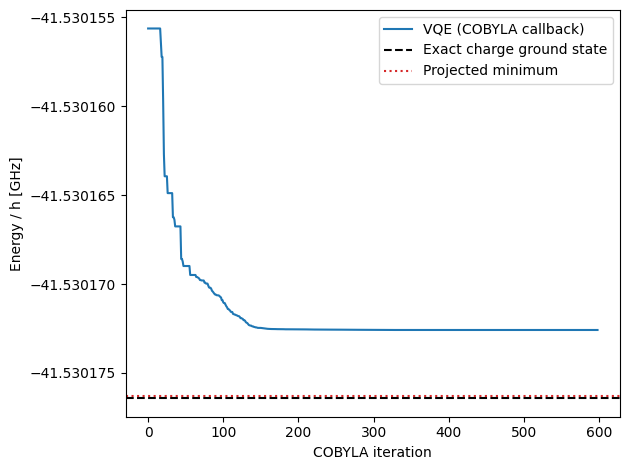

In [17]:
fig, ax = plt.subplots()
ax.plot(
    cost_history_dict["iters"], cost_history_dict["iteration_energy"],
    label="VQE (COBYLA callback)",
)
ax.axhline(E_exact, color="black", linestyle="--", label="Exact charge ground state")
ax.axhline(E_projected, color="tab:red", linestyle=":", label="Projected minimum")
ax.set_xlabel("COBYLA iteration")
ax.set_ylabel("Energy / h [GHz]")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.legend()
fig.tight_layout()
plt.show()

## Results and limitations

With the tested defaults, COBYLA converged in 958 evaluations.

| Quantity | Tested result |
|---|---:|
| Full charge ground energy divided by $h$ | $-41.530176421407$ GHz |
| Four-level projected minimum divided by $h$ | $-41.530176305133$ GHz |
| VQE energy divided by $h$ | $-41.530172584925$ GHz |
| Absolute VQE error | $3.836$ kHz |
| Local-level projection error | $0.116$ kHz |
| Remaining circuit and optimization gap | $3.720$ kHz |
| Charge energy shift from $N=5$ to $N=7$ | $-154.553$ kHz |

The remaining VQE gap includes the ansatz restriction and optimizer termination. The cutoff check tests a separate approximation. VQE uses seven parity-encoded qubits with no padding, and the reconstructed trial has support only on physical charge states. The direct 16-qubit charge encoding has its padding and Pauli decomposition checked separately.

The parameters describe an illustrative effective ring model. Device predictions require extracted circuit parameters and validation of the CPW-coupler treatment. The parity encoding assumes zero offset charges. Stronger coupling can require more local levels or a larger ansatz. The local Estimator includes no gate or shot noise. The compiled trial circuit used 71 CX gates in the tested run.


## Comparison study settings

Keep the physical Hamiltonian, projection and ansatz fixed while varying the starting angles and optimizer. Compare COBYLA, Powell and L-BFGS-B from zero, perturbative, small Gaussian, and broad uniform starts. Use five seeds and a common maximum of 800 objective evaluations. Zero starts are identical across seeds and serve as a deterministic control, with repeated timing measurements.

The noise study compares COBYLA with SPSA from the same perturbative starts, using a separate 600-evaluation cap. Later cells vary the charge cutoff and physical coupling strength separately.

Edit study_seeds, evaluation_budget, noise_budget, shots_grid, measurement_repeats, and target_gap_khz here to change the study size. Figures appear inline. SAVE_FIGURES and SAVE_DATA are both False by default. Set either flag to True only when you want its files exported. The output directory is created when an enabled export runs. These settings print nothing.

In [18]:
# Repeated seeds quantify sensitivity to starting angles and measurement draws.
study_seeds = [11, 22, 33, 44, 55]
initializations = ["Zero", "Perturbative", "Small random", "Uniform random"]
classical_methods = ["COBYLA", "Powell", "L-BFGS-B"]
evaluation_budget = 800
noise_budget = 600
shots_grid = [100, 1000, 10000, 100000, 1000000]
measurement_repeats = 1500
target_gap_khz = 10.0  # Success target relative to the projected minimum [kHz].
SAVE_FIGURES = False  # Set True when ready to export PNG and SVG files.
SAVE_DATA = False     # Set True when ready to export CSV and trace files.
study_output = Path("four_transmon_presentation")
figure_names = []
figure_paths = []
study_runs = []

plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 16, "axes.labelsize": 12,
    "legend.fontsize": 10, "figure.dpi": 100, "savefig.dpi": 240,
    "axes.spines.top": False, "axes.spines.right": False,
})
method_colors = {
    "COBYLA": "#0072B2", "Powell": "#D55E00", "L-BFGS-B": "#009E73",
    "SPSA": "#CC79A7",
}
plot_floor = 1e-6  # Logarithmic plot floor [kHz], used for display only.


def show_figure(fig, name):
    """Display inline and optionally export PNG and SVG files."""
    fig.tight_layout()
    if name not in figure_names:
        figure_names.append(name)
    if SAVE_FIGURES:
        study_output.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "svg"):
            path = study_output / f"{name}.{extension}"
            fig.savefig(path, bbox_inches="tight")
            figure_paths.append(path)
    plt.show()


### Verify a faster repeated statevector calculation

Thousands of trials use direct index permutations to apply the same Pauli rotations as the Qiskit ansatz. Cross-check three seeded random parameter vectors against both the logical circuit and transpiled StatevectorEstimator before using this evaluator.

All optimizer-comparison timings use this same evaluator and exclude initial circuit compilation. They include optimizer and objective-bookkeeping overhead on the local computer. The validation output should confirm agreement. Timing on a QPU would also depend on measurement, queueing and communication. [Qiskit StatevectorEstimator](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.primitives.StatevectorEstimator)

In [19]:
# Apply each real Pauli rotation by index permutations. This is the same
# ideal statevector calculation as the circuit, with less per-call overhead.
basis_indices = np.arange(A.shape[0])
rotation_permutations = []
rotation_signs = []
for mask in masks:
    pivot = (mask & -mask).bit_length() - 1
    rotation_permutations.append(basis_indices ^ mask)
    rotation_signs.append(-(1 - 2 * ((basis_indices >> pivot) & 1)))
rotation_permutations = np.array(rotation_permutations)
rotation_signs = np.array(rotation_signs)


def trial_state(parameters):
    """Simulate the existing ansatz in logical encoded coordinates."""
    state = np.zeros(A.shape[0])
    state[0] = 1.0
    for angle, permutation, signs in zip(
        parameters, rotation_permutations, rotation_signs
    ):
        state = (
            np.cos(angle / 2) * state
            + np.sin(angle / 2) * signs * state[permutation]
        )
    return state


def ideal_energy(state, matrix=A):
    """Return energy [GHz] using a small contraction with stable overhead."""
    return float(np.einsum("i,ij,j->", state.conj(), matrix, state).real)


# Verify several parameter vectors before using the fast evaluator.
for test_seed in (101, 202, 303):
    test_parameters = np.random.default_rng(test_seed).normal(0, 0.3, num_params)
    fast_state = trial_state(test_parameters)
    qiskit_state = Statevector.from_instruction(
        ansatz.decompose().assign_parameters(test_parameters)
    ).data
    assert abs(np.vdot(qiskit_state, fast_state))**2 > 1 - 1e-10
    pub = (ansatz_isa, hamiltonian_isa, test_parameters)
    qiskit_energy = float(
        StatevectorEstimator(seed=seed).run([pub]).result()[0].data.evs.item()
    )
    assert np.isclose(ideal_energy(fast_state), qiskit_energy, atol=1e-9, rtol=0)

projected_values, projected_vectors = np.linalg.eigh(A)
projected_ground = projected_vectors[:, 0]
projected_gap = projected_values[1] - projected_values[0]  # [GHz].
print("Fast simulation agrees with the logical circuit and transpiled Estimator.")

Fast simulation agrees with the logical circuit and transpiled Estimator.


### Independent Pauli measurement noise

For each nonidentity Pauli, sample outcomes +1 and −1 with probabilities $(1\pm\langle P\rangle)/2$. Give each term its own independent batch of S shots. Thus an energy call consumes $76S$ outcomes for this Hamiltonian, and identity contributes no statistical noise.

The standard error is

$$
\sigma_E=\sqrt{\frac{\sum_{\alpha\ne I}c_\alpha^2(1-\langle P_\alpha\rangle^2)}{S}}.
$$

This is a finite-shot measurement model with no commuting-group or shot-allocation optimization. The same helper can apply a global output depolarizing channel to Pauli means. Expect a check of the Pauli energy sum and the number of measured settings.

In [20]:
# A Pauli measurement has outcomes +1 and -1 with probabilities (1 +/- <P>)/2.
# Each nonidentity Pauli gets its own independent batch of shots.
pauli_permutations, pauli_phases = [], []
pauli_labels = hamiltonian.paulis.to_labels()
for label in pauli_labels:
    x_mask = z_mask = n_y = 0
    for bit, letter in enumerate(reversed(label)):
        if letter in "XY":
            x_mask |= 1 << bit
        if letter in "ZY":
            z_mask |= 1 << bit
        n_y += letter == "Y"
    sign = np.ones(A.shape[0])
    for bit in range(num_qubits):
        if z_mask & (1 << bit):
            sign *= 1 - 2 * ((basis_indices >> bit) & 1)
    pauli_permutations.append(basis_indices ^ x_mask)
    pauli_phases.append((1j**n_y) * sign)
pauli_permutations = np.array(pauli_permutations)
pauli_phases = np.array(pauli_phases)
pauli_coefficients = hamiltonian.coeffs.real
identity_terms = np.array([set(label) == {"I"} for label in pauli_labels])
measured_terms = ~identity_terms
n_measured_terms = int(measured_terms.sum())


def pauli_means(state, depolarizing=0.0):
    """Return Pauli means after a global output depolarizing channel."""
    means = np.sum(
        state[pauli_permutations].conj() * pauli_phases * state[None, :],
        axis=1,
    ).real
    means[measured_terms] *= 1 - depolarizing
    return np.clip(means, -1.0, 1.0)


def sampled_energy(state, shots, rng, depolarizing=0.0):
    """Simulate independent finite-shot Pauli measurements [GHz]."""
    means = pauli_means(state, depolarizing)
    estimates = means.copy()
    estimates[measured_terms] = (
        2 * rng.binomial(shots, (1 + means[measured_terms]) / 2) / shots - 1
    )
    return float(pauli_coefficients @ estimates)


def sampling_sigma(state, shots, depolarizing=0.0):
    """Return the exact standard error of the independent-term estimate [GHz]."""
    means = pauli_means(state, depolarizing)
    variance = np.sum(
        pauli_coefficients[measured_terms]**2
        * (1 - means[measured_terms]**2)
    ) / shots
    return float(np.sqrt(max(variance, 0.0)))


test_state = trial_state(x0)
assert np.isclose(
    pauli_coefficients @ pauli_means(test_state), ideal_energy(test_state),
    atol=1e-9, rtol=0,
)
print(f"Finite-shot model uses {n_measured_terms} independent Pauli settings.")

Finite-shot model uses 76 independent Pauli settings.


### Optimizer runner and independent validation

Use the same starting vector for each optimizer within a category and seed. Count every energy call, including finite differences and line-search trials, towards the shared cap. Runs can stop early. If a search requests another call beyond the cap, return the lowest observed trial evaluated so far.

Noisy optimization uses only sampled energies to choose its parameters. After training, evaluate the returned state's ideal energy and ground-state fidelity independently in the simulator. These validation values are never passed to the optimizer. A low sampled energy can occur below the true ground energy because of sampling fluctuations.

SPSA uses two energy calls per update, seeded random perturbations, and averaging of its second-half iterates. Its gain, perturbation schedule and gradient clipping are fixed in the code. The noisy trajectory records ideal energies of current optimizer states. For SPSA, the final point is the averaged state. This cell defines the runners without output. [SciPy minimize](https://docs.scipy.org/doc/scipy-1.16.1/reference/generated/scipy.optimize.minimize.html)

In [21]:
class EvaluationBudgetReached(Exception):
    """End a run exactly at the shared objective-evaluation limit."""


def make_initial(kind, run_seed, matrix=A):
    """Return the same start for every optimizer within a seed and category."""
    random = np.random.default_rng(run_seed)
    if kind == "Zero":
        return np.zeros(num_params)
    if kind == "Perturbative":
        gaps = np.diag(matrix)[masks] - matrix[0, 0]
        return -2 * matrix[masks, 0] / gaps + random.normal(0, 1e-5, num_params)
    if kind == "Small random":
        return random.normal(0, 0.1, num_params)
    if kind == "Uniform random":
        return random.uniform(-np.pi, np.pi, num_params)
    raise ValueError(f"Unknown initialization {kind}")


def optimize_run(method, kind, run_seed, budget, shots=None, matrix=A,
                 reference=E_exact, projected_reference=E_projected,
                 track_iterates=False):
    """Run one optimizer and validate its returned state independently."""
    start_parameters = make_initial(kind, run_seed, matrix)
    noise_rng = np.random.default_rng(run_seed + 100000)
    observed, ideal_trace, incumbent_ideal, timestamps = [], [], [], []
    best_observed = np.inf
    best_parameters = start_parameters.copy()
    best_true_energy = np.inf
    fidelity_reference = projected_ground if matrix is A else np.linalg.eigh(matrix)[1][:, 0]
    iterate_nfev = [0]
    iterate_energy = [ideal_energy(trial_state(start_parameters), matrix)]
    started = perf_counter()

    def validate_iterate(parameters):
        if track_iterates:
            iterate_nfev.append(len(observed))
            iterate_energy.append(ideal_energy(trial_state(parameters), matrix))

    def objective(parameters):
        nonlocal best_observed, best_parameters, best_true_energy
        if len(observed) >= budget:
            raise EvaluationBudgetReached
        state = trial_state(parameters)
        true_energy = ideal_energy(state, matrix)
        value = true_energy if shots is None else sampled_energy(state, shots, noise_rng)
        if value < best_observed:
            best_observed = value
            best_parameters = np.copy(parameters)
            best_true_energy = true_energy
        observed.append(value)
        ideal_trace.append(true_energy)
        incumbent_ideal.append(best_true_energy)
        timestamps.append(perf_counter() - started)
        return value

    try:
        if method == "SPSA":
            # Two perturbed evaluations per update, followed by iterate averaging.
            parameters = start_parameters.copy()
            tail = []
            steps = (budget - 1) // 2
            for iteration in range(steps):
                delta = noise_rng.choice([-1.0, 1.0], size=num_params)
                c = 0.02 / (iteration + 1)**0.101  # Perturbation [radians].
                gain = 0.02 / (iteration + 21)**0.602
                plus = objective(parameters + c * delta)
                minus = objective(parameters - c * delta)
                gradient = (plus - minus) * delta / (2 * c)
                parameters -= gain * np.clip(gradient, -5, 5)
                validate_iterate(parameters)
                if iteration >= steps // 2:
                    tail.append(parameters.copy())
            final_parameters = np.mean(tail, axis=0)
            objective(final_parameters)
            termination = "SPSA update budget"
            reported_success = False
            selection = "Average of second-half SPSA iterates"
        else:
            options = {
                "COBYLA": {"maxiter": budget, "rhobeg": 0.1, "tol": 1e-7},
                "Powell": {"maxfev": budget, "xtol": 1e-6, "ftol": 1e-10},
                "L-BFGS-B": {"maxfun": budget, "maxiter": budget,
                            "ftol": 1e-12, "gtol": 1e-7},
            }[method]
            result = minimize(objective, start_parameters, method=method, options=options,
                              callback=validate_iterate if track_iterates else None)
            final_parameters = result.x.copy()
            reported_success = bool(result.success)
            termination = str(result.message)
            selection = "Optimizer returned state"
    except EvaluationBudgetReached:
        final_parameters = best_parameters.copy()
        reported_success = False
        termination = "Shared evaluation budget"
        selection = "Lowest observed evaluation at budget limit"

    validate_iterate(final_parameters)
    wall_s = perf_counter() - started
    final_state = trial_state(final_parameters)
    final_energy = ideal_energy(final_state, matrix)
    fidelity = float(abs(np.vdot(fidelity_reference, final_state))**2)
    record = {
        "optimizer": method, "initialization": kind, "seed": int(run_seed),
        "shots_per_term": 0 if shots is None else int(shots),
        "nfev": len(observed), "wall_s": wall_s, "energy_ghz": final_energy,
        "charge_error_khz": abs(final_energy - reference) * 1e6,
        "projected_gap_khz": (final_energy - projected_reference) * 1e6,
        "fidelity_projected": fidelity,
        "success_target": bool((final_energy - projected_reference) * 1e6 <= target_gap_khz),
        "reported_success": reported_success, "termination": termination,
        "selection": selection,
        "total_measurement_shots": 0 if shots is None else len(observed) * shots * n_measured_terms,
        "parameters": final_parameters, "observed": np.array(observed),
        "ideal_trace": np.array(ideal_trace), "incumbent_ideal": np.array(incumbent_ideal),
        "timestamps": np.array(timestamps),
        "iterate_nfev": np.array(iterate_nfev), "iterate_energy": np.array(iterate_energy),
    }
    return record


def select_runs(method=None, kind=None, shots=0, source=None):
    """Select comparable run records for tables and plots."""
    records = study_runs if source is None else source
    return [
        record for record in records
        if (method is None or record["optimizer"] == method)
        and (kind is None or record["initialization"] == kind)
        and record["shots_per_term"] == shots
    ]


def aligned_trace(records, key, length):
    """Hold the last recorded value after a run stops."""
    return np.array([
        np.pad(record[key], (0, length - len(record[key])), mode="edge")
        for record in records
    ])

### Run the noiseless study

Warm the simulation kernel and randomize job order to reduce timing-order effects. Run three optimizers, four starts, and five seeds. Expect 60 completed records. A budget-limited run remains part of the comparison and is identified in the CSV.

In [22]:
# Warm the kernel before timing and randomize job order to reduce order effects.
for _ in range(5):
    ideal_energy(trial_state(x0))
jobs = [(method, kind, run_seed) for method in classical_methods
        for kind in initializations for run_seed in study_seeds]
job_rng = np.random.default_rng(seed)
for job_number in job_rng.permutation(len(jobs)):
    method, kind, run_seed = jobs[job_number]
    study_runs.append(optimize_run(method, kind, run_seed, evaluation_budget))
print(f"Completed {len(study_runs)} noiseless comparisons.")

Completed 60 noiseless comparisons.


### Figure 1  Convergence from different starts

Plot median best-evaluated energy gaps across seeds against objective evaluations. Shading shows the interquartile range. The dashed line marks the 10 kHz target above the projected minimum. Extend a stopped run's final recorded value to the cap for plotting. Each panel has its own vertical range.

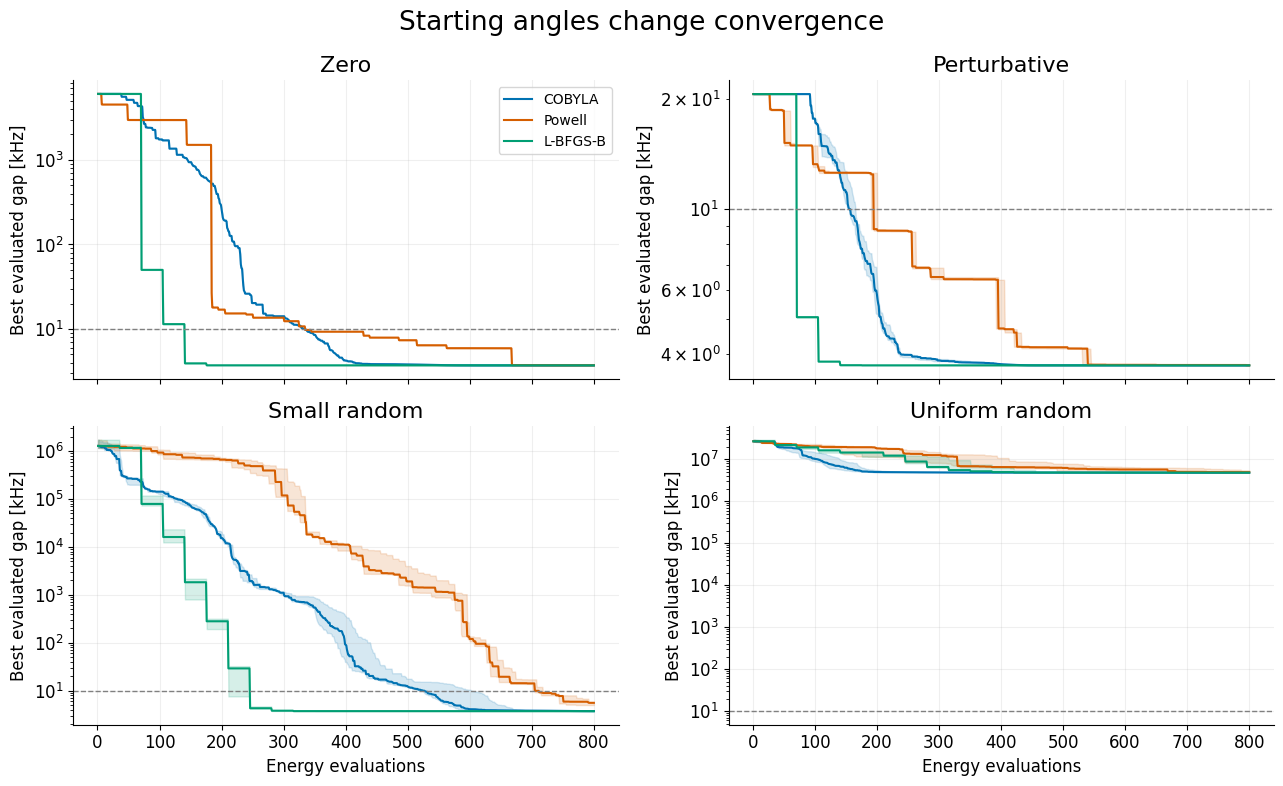

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, kind in zip(axes.ravel(), initializations):
    for method in classical_methods:
        records = select_runs(method, kind)
        traces = (aligned_trace(records, "observed", evaluation_budget) - E_projected) * 1e6
        traces = np.minimum.accumulate(traces, axis=1)
        low, median, high = np.quantile(traces, [0.25, 0.5, 0.75], axis=0)
        x = np.arange(1, evaluation_budget + 1)
        ax.plot(x, np.maximum(median, plot_floor), label=method, color=method_colors[method])
        ax.fill_between(x, np.maximum(low, plot_floor), np.maximum(high, plot_floor),
                        color=method_colors[method], alpha=0.16)
    ax.axhline(target_gap_khz, color="gray", ls="--", lw=1)
    ax.set(title=kind, yscale="log", ylabel="Best evaluated gap [kHz]")
    ax.grid(alpha=0.2)
axes[1, 0].set_xlabel("Energy evaluations")
axes[1, 1].set_xlabel("Energy evaluations")
axes[0, 0].legend()
fig.suptitle("Starting angles change convergence", fontsize=19)
show_figure(fig, "01_convergence_by_initialization")

### Figure 2  Accuracy by optimizer and start

Compare median returned-state energy gaps above the projected minimum. The color scale is logarithmic. Large errors from broad random starts indicate failure to reach the target within this evaluation cap.

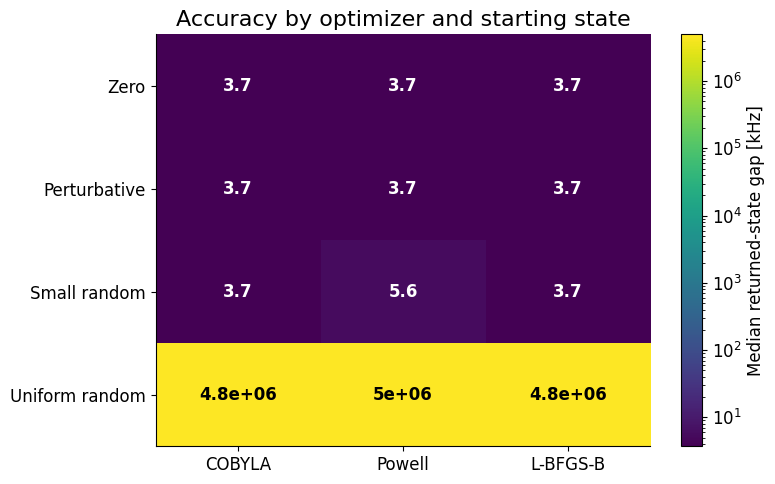

In [24]:
median_gaps = np.array([
    [np.median([r["projected_gap_khz"] for r in select_runs(method, kind)])
     for method in classical_methods] for kind in initializations
])
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(np.maximum(median_gaps, plot_floor), aspect="auto",
               norm=LogNorm(vmin=max(median_gaps.min(), plot_floor),
                            vmax=max(median_gaps.max(), plot_floor * 10)), cmap="viridis")
ax.set_xticks(range(len(classical_methods)), classical_methods)
ax.set_yticks(range(len(initializations)), initializations)
for i in range(len(initializations)):
    for j in range(len(classical_methods)):
        ax.text(j, i, f"{median_gaps[i,j]:.2g}", ha="center", va="center",
                color="black" if im.norm(median_gaps[i,j]) > 0.65 else "white",
                weight="bold")
fig.colorbar(im, ax=ax, label="Median returned-state gap [kHz]")
ax.set_title("Accuracy by optimizer and starting state")
show_figure(fig, "02_accuracy_heatmap")

### Figure 3  Local time and energy evaluations

Show wall time and actual evaluation counts across all starting categories. Points show individual runs. Timing uses the shared fast simulation kernel and includes classical optimizer overhead. These are measurements on the execution computer.

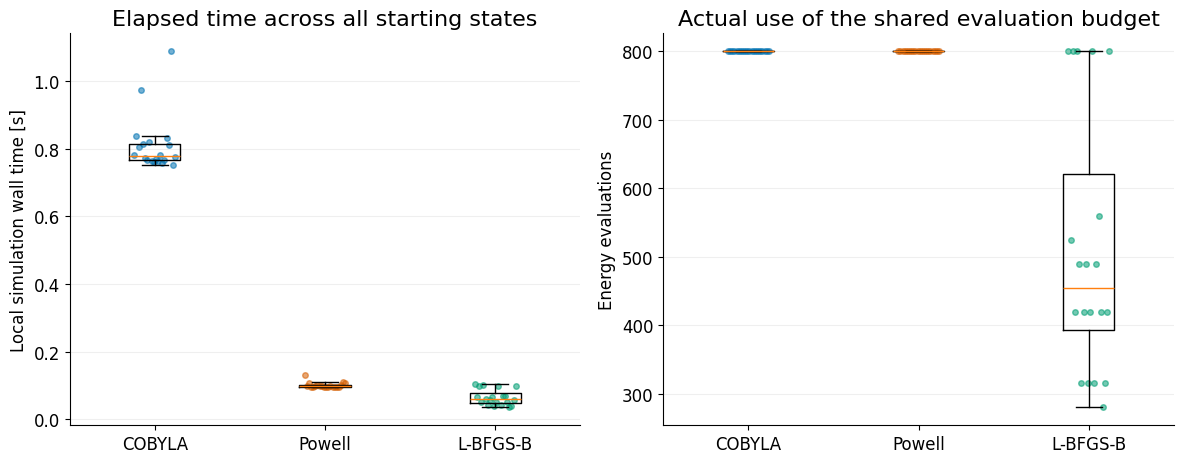

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, field, ylabel in [
    (axes[0], "wall_s", "Local simulation wall time [s]"),
    (axes[1], "nfev", "Energy evaluations"),
]:
    data = [[r[field] for r in select_runs(method)] for method in classical_methods]
    ax.boxplot(data, tick_labels=classical_methods, showfliers=False)
    for index, values in enumerate(data, start=1):
        offsets = np.linspace(-0.12, 0.12, len(values))
        ax.scatter(index + offsets, values, s=16, alpha=0.55,
                   color=method_colors[classical_methods[index-1]])
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_title("Elapsed time across all starting states")
axes[1].set_title("Actual use of the shared evaluation budget")
show_figure(fig, "03_time_and_evaluation_cost")

### Figure 4  Accuracy and time

Compare every returned state's energy gap with its run time. Color identifies the optimizer and marker shape identifies initialization. This plot shows whether a fast run also gives an accurate answer.

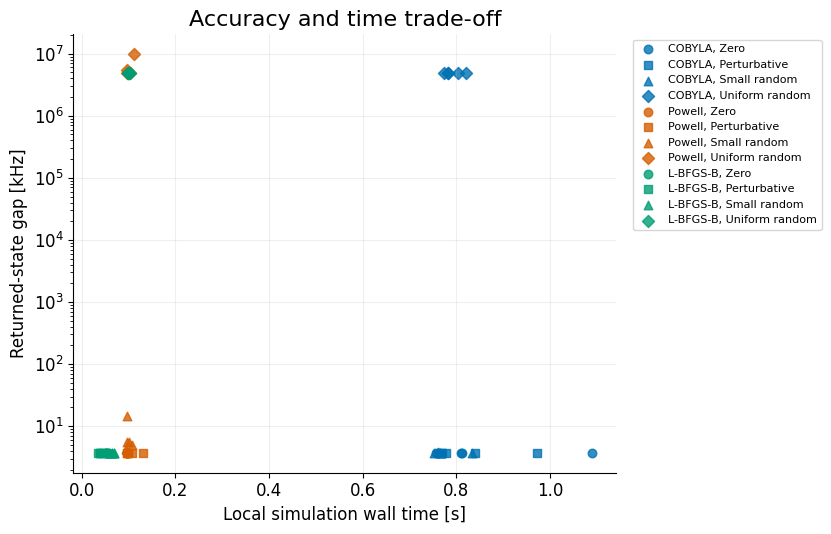

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
markers = ["o", "s", "^", "D"]
for method in classical_methods:
    for kind, marker in zip(initializations, markers):
        records = select_runs(method, kind)
        ax.scatter([r["wall_s"] for r in records],
                   [max(r["projected_gap_khz"], plot_floor) for r in records],
                   color=method_colors[method], marker=marker, alpha=0.8,
                   label=f"{method}, {kind}", s=38)
ax.set(xlabel="Local simulation wall time [s]", ylabel="Returned-state gap [kHz]",
       yscale="log", title="Accuracy and time trade-off")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.grid(alpha=0.2)
show_figure(fig, "04_accuracy_vs_time")

### Figure 5  Success within the budget

Success means a returned ideal energy within target_gap_khz of the projected minimum. This criterion is independent of SciPy's termination flag. Display fractions over five seeds, which are descriptive proportions with a small sample size.

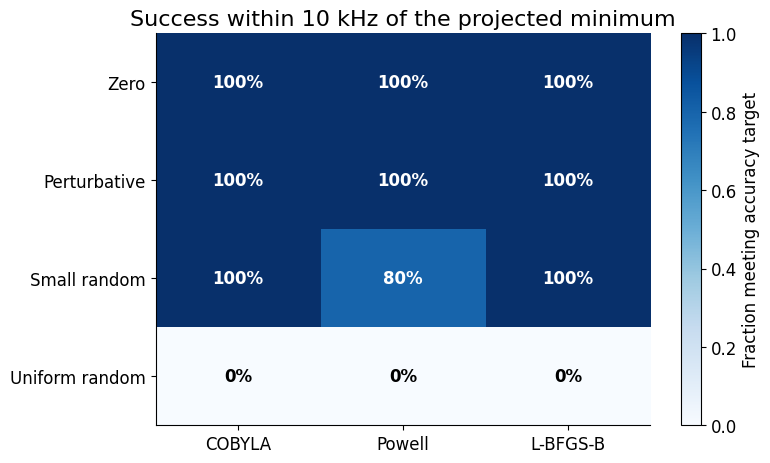

In [27]:
success_rates = np.array([
    [np.mean([r["success_target"] for r in select_runs(method, kind)])
     for method in classical_methods] for kind in initializations
])
fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(success_rates, vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(classical_methods)), classical_methods)
ax.set_yticks(range(len(initializations)), initializations)
for i in range(len(initializations)):
    for j in range(len(classical_methods)):
        ax.text(j, i, f"{success_rates[i,j]:.0%}", ha="center", va="center",
                color="white" if success_rates[i,j] > 0.6 else "black", weight="bold")
fig.colorbar(im, ax=ax, label="Fraction meeting accuracy target")
ax.set_title(f"Success within {target_gap_khz:g} kHz of the projected minimum")
show_figure(fig, "05_success_rates")

### Figure 6  State fidelity and populations

Compare energy gaps with $1-F$, where $F=|\langle\psi_0|\psi\rangle|^2$ uses the projected ground eigenvector for validation only. The dashed bound follows from $1-F\le(E-E_0)/(E_1-E_0)$.

Compare the eight largest projected ground-state populations with the best VQE state. The basis labels list local levels for transmons 4 through 1. This checks wavefunction quality as well as energy.

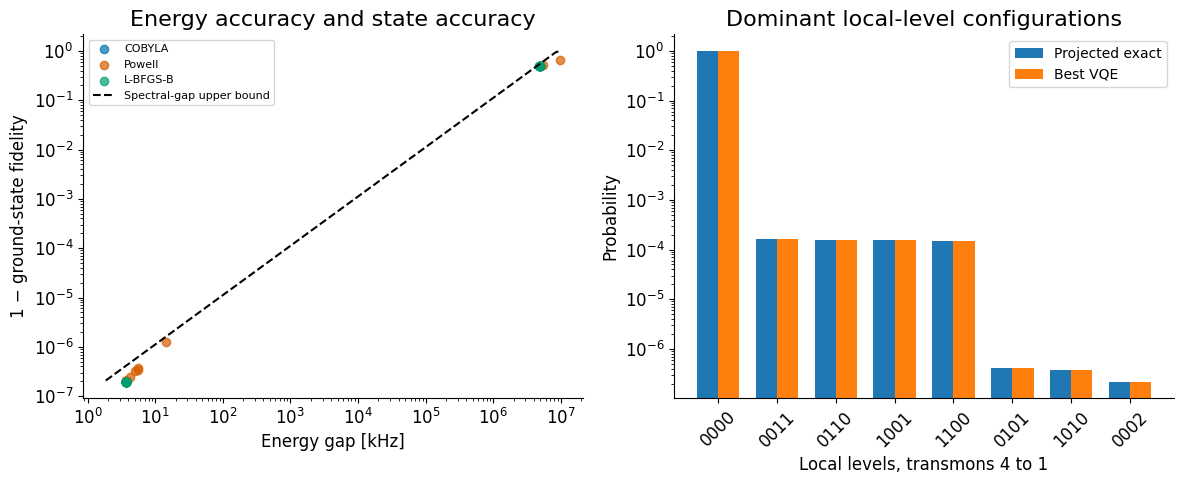

In [28]:
best_run = min(study_runs, key=lambda r: r["energy_ghz"])
best_state = trial_state(best_run["parameters"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for method in classical_methods:
    records = select_runs(method)
    axes[0].scatter([max(r["projected_gap_khz"], plot_floor) for r in records],
                    [max(1-r["fidelity_projected"], 1e-12) for r in records],
                    color=method_colors[method], label=method, alpha=0.7)
gap_line = np.geomspace(
    max(plot_floor, min(r["projected_gap_khz"] for r in study_runs) / 2),
    max(r["projected_gap_khz"] for r in study_runs), 100
)
axes[0].plot(gap_line, np.minimum(1, gap_line / (projected_gap * 1e6)),
             color="black", ls="--", label="Spectral-gap upper bound")
axes[0].set(xscale="log", yscale="log", xlabel="Energy gap [kHz]",
            ylabel="1 − ground-state fidelity", title="Energy accuracy and state accuracy")
axes[0].legend(fontsize=8)
top = np.argsort(np.abs(projected_ground)**2)[-8:][::-1]
x = np.arange(len(top))
axes[1].bar(x-0.18, np.abs(projected_ground[top])**2, width=0.36, label="Projected exact")
axes[1].bar(x+0.18, np.abs(best_state[top])**2, width=0.36, label="Best VQE")
axes[1].set_xticks(x, ["".join(str(a) for a in level_labels[i][::-1]) for i in top],
                   rotation=45)
axes[1].set(yscale="log", ylabel="Probability", xlabel="Local levels, transmons 4 to 1",
            title="Dominant local-level configurations")
axes[1].legend()
show_figure(fig, "06_fidelity_and_state_populations")

### Figure 7  Measurement uncertainty versus shot count

Hold the best optimized state fixed and repeat energy sampling 1,500 times for each shot count. Compare empirical root-mean-square measurement error with the predicted standard error. The expected scaling is $S^{-1/2}$. The horizontal line shows the ideal VQE optimization gap for context.

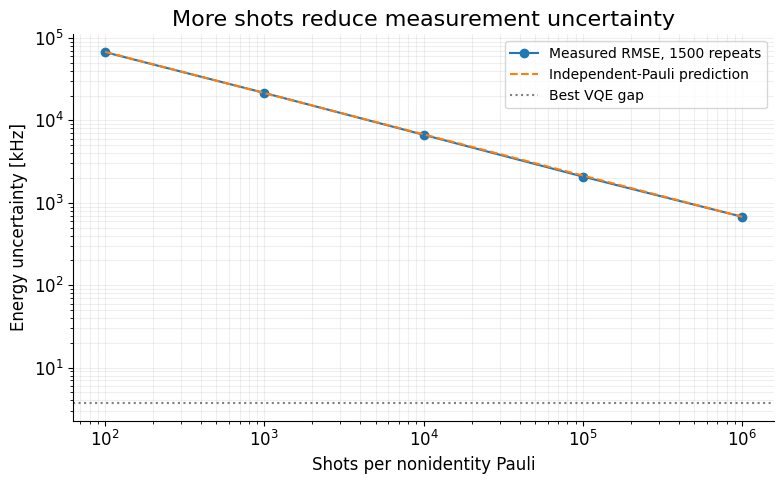

In [29]:
# Isolate measurement statistics at one fixed optimized state.
shot_statistics = []
measurement_samples = {}
measure_rng = np.random.default_rng(seed + 200000)
means_best = pauli_means(best_state)
for shots in shots_grid:
    samples = np.array([
        sampled_energy(best_state, shots, measure_rng)
        for _ in range(measurement_repeats)
    ])
    errors = samples - ideal_energy(best_state)
    measurement_samples[shots] = errors
    shot_statistics.append({
        "shots_per_term": shots,
        "total_shots_per_energy": shots * n_measured_terms,
        "empirical_rmse_khz": float(np.sqrt(np.mean(errors**2)) * 1e6),
        "predicted_sigma_khz": sampling_sigma(best_state, shots) * 1e6,
        "empirical_bias_khz": float(np.mean(errors) * 1e6),
    })
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(shots_grid, [r["empirical_rmse_khz"] for r in shot_statistics],
          "o-", label=f"Measured RMSE, {measurement_repeats} repeats")
ax.loglog(shots_grid, [r["predicted_sigma_khz"] for r in shot_statistics],
          "--", label="Independent-Pauli prediction")
ax.axhline(best_run["projected_gap_khz"], color="gray", ls=":", label="Best VQE gap")
ax.set(xlabel="Shots per nonidentity Pauli", ylabel="Energy uncertainty [kHz]",
       title="More shots reduce measurement uncertainty")
ax.legend()
ax.grid(which="both", alpha=0.2)
show_figure(fig, "07_shot_noise_scaling")

### Figure 8  Distribution of measurement errors

Show signed measured-minus-ideal errors at 1,000 and 100,000 shots per Pauli. The axes use MHz for readable tick labels. Negative estimates are statistical fluctuations. Both panels use the same fixed state and separate horizontal scales.

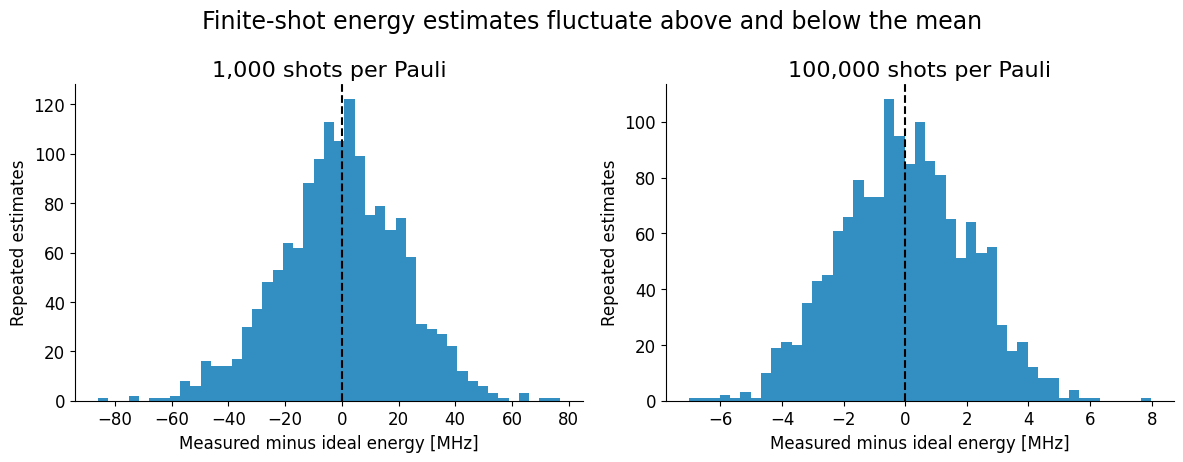

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, shots in zip(axes, (1000, 100000)):
    errors = measurement_samples[shots] * 1000
    ax.hist(errors, bins=45, alpha=0.8, color="#0072B2")
    ax.axvline(0, color="black", ls="--")
    ax.set(title=f"{shots:,} shots per Pauli", xlabel="Measured minus ideal energy [MHz]",
           ylabel="Repeated estimates")
fig.suptitle("Finite-shot energy estimates fluctuate above and below the mean", fontsize=17)
show_figure(fig, "08_measurement_error_distributions")

### Run optimization with finite-shot noise

Compare COBYLA and SPSA under ideal, 10,000-shot, and 100,000-shot objectives, with five seeds each. Every case starts near the perturbative product state and receives the same maximum number of energy evaluations. SPSA averaging is part of its defined procedure. Expect 30 run records.

In [31]:
noisy_runs = []
noise_jobs = [(method, shots, run_seed)
              for method in ("COBYLA", "SPSA")
              for shots in (None, 10000, 100000)
              for run_seed in study_seeds]
for job_number in np.random.default_rng(seed + 1).permutation(len(noise_jobs)):
    method, shots, run_seed = noise_jobs[job_number]
    noisy_runs.append(optimize_run(
        method, "Perturbative", run_seed, noise_budget, shots=shots, track_iterates=True
    ))
print(f"Completed {len(noisy_runs)} ideal and finite-shot optimization runs.")

Completed 30 ideal and finite-shot optimization runs.


### Figure 9  Optimizer states during noisy training

Validate the current accepted optimizer states at their corresponding energy-evaluation counts. For SciPy, use iteration callbacks. For SPSA, use the parameter update after each pair of measurements and the final averaged state. Ideal validation is diagnostic and does not affect the noisy update.

Lines show medians and shading shows interquartile ranges. Holding the last state to the cap permits comparison after early stopping.

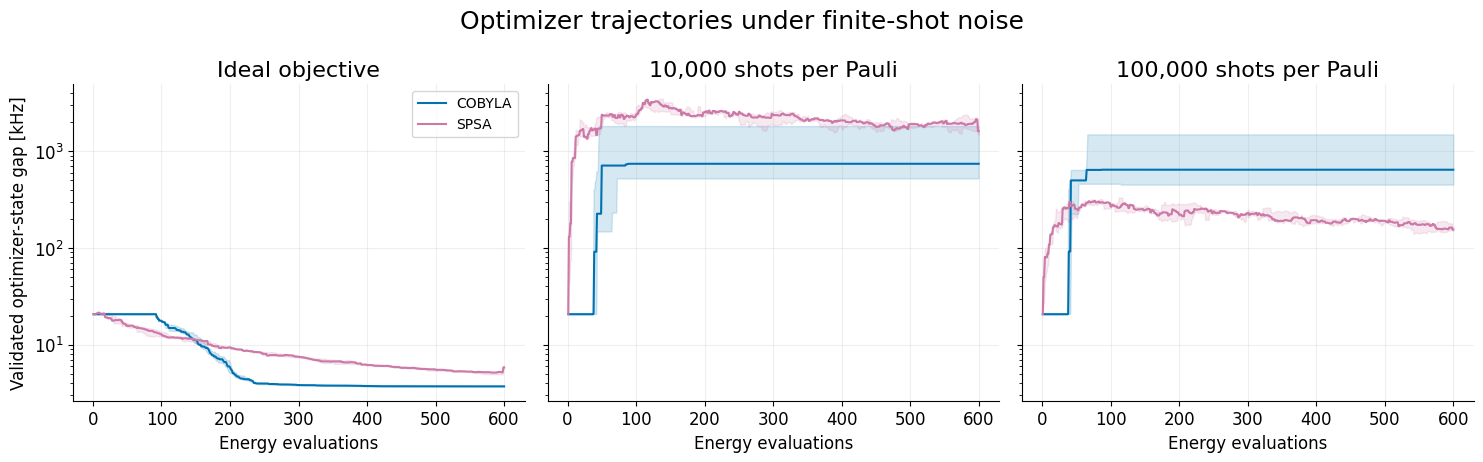

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharey=True)
for ax, shots in zip(axes, (0, 10000, 100000)):
    for method in ("COBYLA", "SPSA"):
        records = select_runs(method, shots=shots, source=noisy_runs)
        traces = []
        for record in records:
            query_counts = np.arange(1, noise_budget + 1)
            positions = np.searchsorted(record["iterate_nfev"], query_counts, side="right") - 1
            traces.append((record["iterate_energy"][positions] - E_projected) * 1e6)
        traces = np.array(traces)
        low, median, high = np.quantile(traces, [0.25, 0.5, 0.75], axis=0)
        x = np.arange(1, noise_budget + 1)
        ax.plot(x, np.maximum(median, plot_floor), color=method_colors[method], label=method)
        ax.fill_between(x, np.maximum(low, plot_floor), np.maximum(high, plot_floor),
                        color=method_colors[method], alpha=0.16)
    ax.set(title="Ideal objective" if shots == 0 else f"{shots:,} shots per Pauli",
           xlabel="Energy evaluations", yscale="log")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Validated optimizer-state gap [kHz]")
axes[0].legend()
fig.suptitle("Optimizer trajectories under finite-shot noise", fontsize=18)
show_figure(fig, "09_noisy_optimizer_trajectories")

### Figure 10  Validated final accuracy and shot cost

Validate each returned state without sampling noise. Show medians, interquartile ranges, and individual seeds. The second panel counts actual measurement outcomes used during training, including early stopping. Equal evaluation caps do not imply equal total shots when S differs.

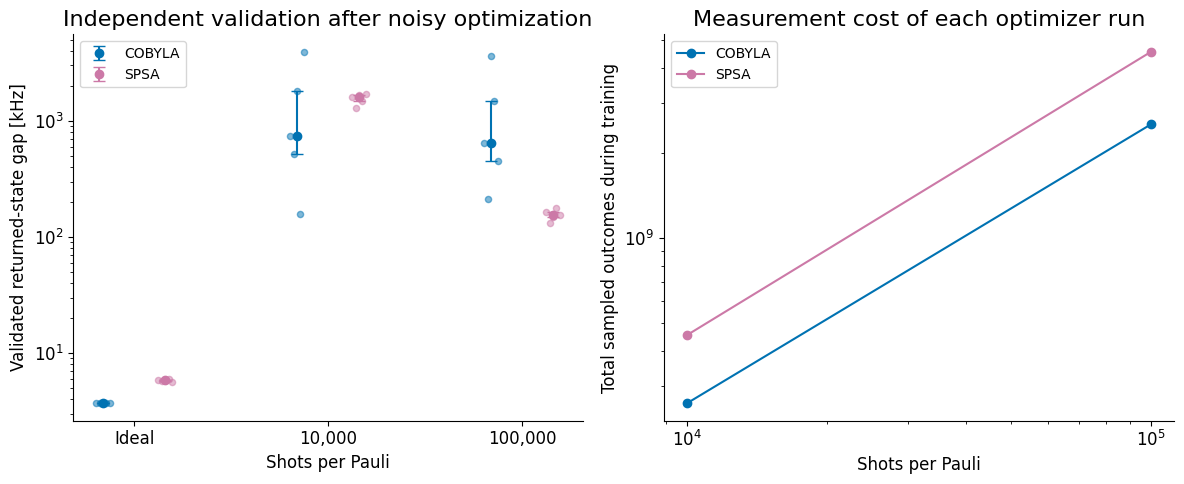

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(3)
conditions = ["Ideal", "10,000", "100,000"]
for offset, method in zip((-0.16, 0.16), ("COBYLA", "SPSA")):
    for index, shots in enumerate((0, 10000, 100000)):
        records = select_runs(method, shots=shots, source=noisy_runs)
        errors = np.array([r["projected_gap_khz"] for r in records])
        median = np.median(errors)
        lo, hi = np.quantile(errors, [0.25, 0.75])
        axes[0].errorbar(index + offset, max(median, plot_floor),
                         yerr=[[median-lo], [hi-median]], fmt="o",
                         color=method_colors[method], capsize=4,
                         label=method if index == 0 else None)
        axes[0].scatter(index + offset + np.linspace(-0.035,0.035,len(errors)),
                        np.maximum(errors,plot_floor), color=method_colors[method], alpha=0.5, s=20)
    shot_totals = [
        np.median([r["total_measurement_shots"] for r in select_runs(
            method, shots=shots, source=noisy_runs)])
        for shots in (10000, 100000)
    ]
    axes[1].plot([10000,100000], shot_totals, "o-", color=method_colors[method], label=method)
axes[0].set_xticks(x, conditions)
axes[0].set(yscale="log", xlabel="Shots per Pauli", ylabel="Validated returned-state gap [kHz]",
            title="Independent validation after noisy optimization")
axes[0].legend()
axes[1].set(xscale="log", yscale="log", xlabel="Shots per Pauli",
            ylabel="Total sampled outcomes during training",
            title="Measurement cost of each optimizer run")
axes[1].legend()
show_figure(fig, "10_noise_accuracy_and_shot_cost")

### Figure 11  Global output depolarizing noise

Apply $\rho\mapsto(1-p)\rho+pI/128$ to the fixed best state on the seven encoded qubits. Plot the expected energy shift and fidelity.

This channel changes the cost affinely,

$$E_p=(1-p)E+p\,\mathrm{Tr}(A)/128.$$

For a state-independent p below one, it leaves the ideal minimizer unchanged while biasing energies and mixing the output state. This simplified channel has no calibrated gate, readout, relaxation, or leakage model. It stays inside the retained encoded space.

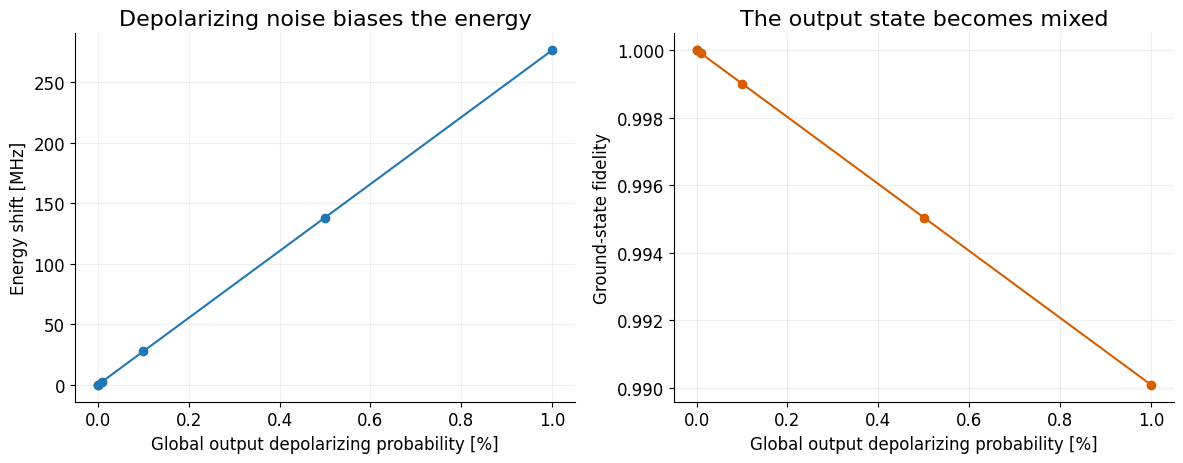

In [34]:
# A global output depolarizing channel is rho -> (1-p)rho + p I/d.
# It changes the energy affinely and leaves the ideal minimizing state unchanged.
depolarizing_rates = np.array([0, 1e-5, 1e-4, 1e-3, 0.005, 0.01])
ideal_best = ideal_energy(best_state)
trace_mean = np.trace(A).real / A.shape[0]
depolarized_energies = (1-depolarizing_rates)*ideal_best + depolarizing_rates*trace_mean
depolarized_fidelities = (
    (1-depolarizing_rates)*abs(np.vdot(projected_ground,best_state))**2
    + depolarizing_rates/A.shape[0]
)
for p, energy in zip(depolarizing_rates, depolarized_energies):
    assert np.isclose(pauli_coefficients @ pauli_means(best_state,p), energy, atol=1e-9)
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
axes[0].plot(100*depolarizing_rates, (depolarized_energies-ideal_best)*1000, "o-")
axes[0].set(xlabel="Global output depolarizing probability [%]",
            ylabel="Energy shift [MHz]", title="Depolarizing noise biases the energy")
axes[1].plot(100*depolarizing_rates, depolarized_fidelities, "o-", color="#D55E00")
axes[1].set(xlabel="Global output depolarizing probability [%]",
            ylabel="Ground-state fidelity", title="The output state becomes mixed")
for ax in axes:
    ax.grid(alpha=0.2)
show_figure(fig,"11_depolarizing_noise")

### Figure 12  Charge-cutoff convergence

Recalculate sparse charge references for N from 3 to 7 with eigenpair residual checks. Compare shifts relative to N=7. This is a finite-cutoff convergence test, and N=7 is the comparison reference for this figure.

/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_60355/4152350657.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  return h, sp.diags(n, format="csr")


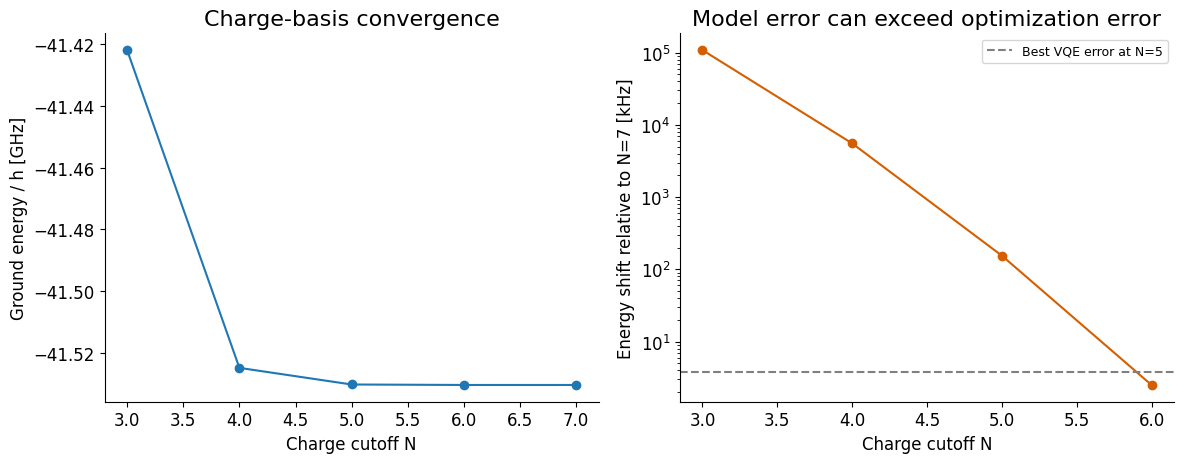

In [35]:
cutoff_records = []
for cutoff in (3,4,5,6,7):
    local_models = [local_hamiltonian(ec,ej,cutoff) for ec,ej in zip(E_C,E_J)]
    matrix = build_hamiltonian([pair[0] for pair in local_models],
                               [pair[1] for pair in local_models])
    eig, vec = eigsh(matrix,k=1,which="SA",tol=1e-11,
                    v0=np.random.default_rng(seed).normal(size=matrix.shape[0]))
    residual = float(np.linalg.norm(matrix@vec[:,0]-eig[0]*vec[:,0]))
    assert residual < 1e-7
    cutoff_records.append({"cutoff":cutoff,"energy_ghz":float(eig[0]),
                           "dimension":matrix.shape[0],"residual_ghz":residual})
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
cutoff_x = [r["cutoff"] for r in cutoff_records]
energies = np.array([r["energy_ghz"] for r in cutoff_records])
axes[0].plot(cutoff_x, energies,"o-")
axes[0].ticklabel_format(axis="y",style="plain",useOffset=False)
axes[0].set(xlabel="Charge cutoff N",ylabel="Ground energy / h [GHz]",
            title="Charge-basis convergence")
axes[1].semilogy(cutoff_x[:-1],(energies[:-1]-energies[-1])*1e6,"o-",color="#D55E00")
axes[1].axhline(best_run["charge_error_khz"],ls="--",color="gray",
                label="Best VQE error at N=5")
axes[1].set(xlabel="Charge cutoff N",ylabel="Energy shift relative to N=7 [kHz]",
            title="Model error can exceed optimization error")
axes[1].legend(fontsize=9)
show_figure(fig,"12_charge_cutoff_convergence")

### Figure 13  Physical coupling sweep

Multiply every ring coupling by a common factor from zero to 1.5. Hold local energies and charge cutoff fixed. For each factor, calculate charge and projected reference energies and run one perturbatively initialized COBYLA optimization.

Separate the local-level projection error from the remaining VQE gap. These are illustrative effective-model predictions, using one start per coupling point.

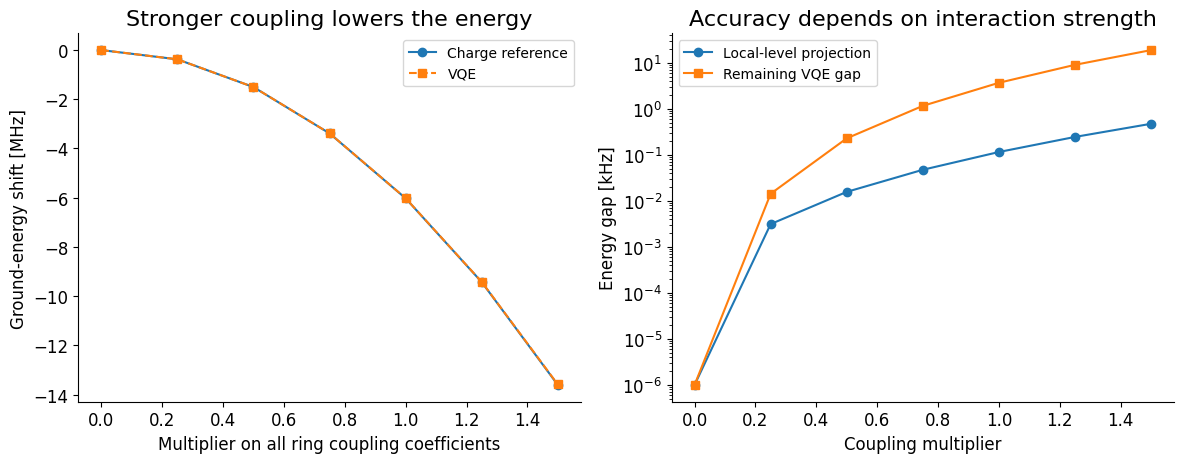

In [36]:
# Scale only the effective charge couplings, holding all local parameters fixed.
local_level_diag = np.zeros_like(A)
for index, levels in enumerate(level_labels):
    local_level_diag[index,index] = sum(local_e[site][level]
                                        for site,level in enumerate(levels))
coupling_level = A - local_level_diag
charge_local = sp.csr_matrix(H.shape)
for site,h in enumerate(local_h):
    ops = [sp.eye(d,format="csr")]*4
    ops[site] = h
    charge_local += tensor_sparse(ops)
charge_coupling = H - charge_local
coupling_records = []
for scale in (0,0.25,0.5,0.75,1.0,1.25,1.5):
    projected_matrix = local_level_diag + scale*coupling_level
    projected_energy = float(np.linalg.eigvalsh(projected_matrix)[0])
    charge_matrix = charge_local + scale*charge_coupling
    eig = eigsh(charge_matrix,k=1,which="SA",tol=1e-11,return_eigenvectors=False,
                 v0=np.random.default_rng(seed).normal(size=H.shape[0]))
    charge_energy = float(eig[0])
    run = optimize_run("COBYLA","Perturbative",study_seeds[0],evaluation_budget,
                       matrix=projected_matrix,reference=charge_energy,
                       projected_reference=projected_energy)
    coupling_records.append({
        "scale":scale,"charge_energy_ghz":charge_energy,
        "projected_energy_ghz":projected_energy,"vqe_energy_ghz":run["energy_ghz"],
        "projection_error_khz":(projected_energy-charge_energy)*1e6,
        "vqe_gap_khz":run["projected_gap_khz"],"nfev":run["nfev"],
    })
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
scale_x = [r["scale"] for r in coupling_records]
uncoupled_reference = coupling_records[0]["charge_energy_ghz"]
axes[0].plot(scale_x,[(r["charge_energy_ghz"]-uncoupled_reference)*1000
                      for r in coupling_records],"o-",label="Charge reference")
axes[0].plot(scale_x,[(r["vqe_energy_ghz"]-uncoupled_reference)*1000
                      for r in coupling_records],"s--",label="VQE")
axes[0].set(xlabel="Multiplier on all ring coupling coefficients",
            ylabel="Ground-energy shift [MHz]",title="Stronger coupling lowers the energy")
axes[0].legend()
axes[1].semilogy(scale_x,np.maximum([r["projection_error_khz"] for r in coupling_records],plot_floor),
                "o-",label="Local-level projection")
axes[1].semilogy(scale_x,np.maximum([r["vqe_gap_khz"] for r in coupling_records],plot_floor),
                "s-",label="Remaining VQE gap")
axes[1].set(xlabel="Coupling multiplier",ylabel="Energy gap [kHz]",
            title="Accuracy depends on interaction strength")
axes[1].legend()
show_figure(fig,"13_coupling_strength_sweep")

### Figure 14  Error scales

Compare the N=5-to-7 charge shift, four-level projection error, best returned VQE gap, and predicted shot standard error at 100,000 shots per Pauli. The first three are deterministic energy differences and the fourth is a statistical standard deviation. They are plotted as distinct scales and should not be added directly.

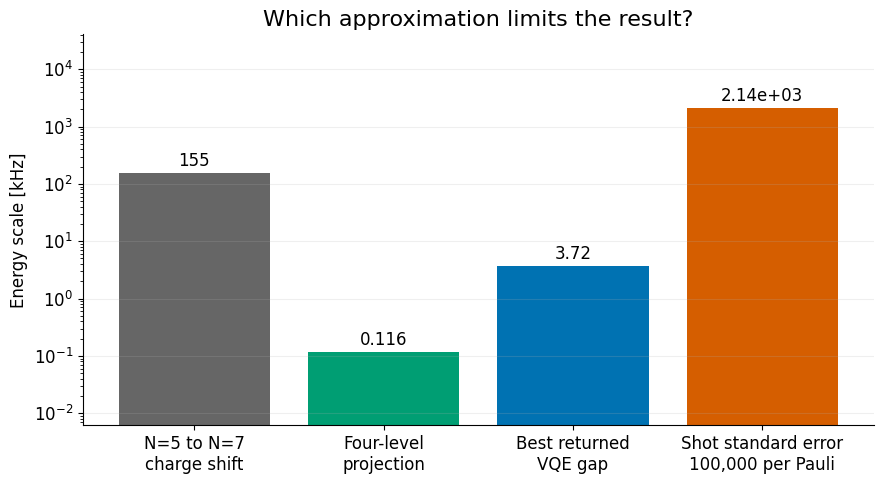

In [37]:
fig, ax = plt.subplots(figsize=(9,5))
cutoff_shift = abs(cutoff_records[-1]["energy_ghz"]-E_exact)*1e6
error_components = [
    cutoff_shift,(E_projected-E_exact)*1e6,
    max(best_run["projected_gap_khz"],plot_floor),
    sampling_sigma(best_state,100000)*1e6,
]
labels = ["N=5 to N=7\ncharge shift","Four-level\nprojection",
          "Best returned\nVQE gap","Shot standard error\n100,000 per Pauli"]
bars = ax.bar(labels,error_components,color=["#666666","#009E73","#0072B2","#D55E00"])
ax.set(yscale="log",ylabel="Energy scale [kHz]",
       title="Which approximation limits the result?")
for bar,value in zip(bars,error_components):
    ax.annotate(f"{value:.3g}",(bar.get_x()+bar.get_width()/2,value),
                 xytext=(0,5),textcoords="offset points",ha="center")
ax.margins(y=0.3)
ax.grid(axis="y",alpha=0.2)
show_figure(fig,"14_error_budget")

### Optional result exports

Display the summary below. With SAVE_DATA set to True, also export CSV tables, compressed optimization traces, and a JSON summary. SAVE_FIGURES separately controls PNG and SVG exports. The summary records the run budgets, seeds, noise assumptions and execution environment. Figures with logarithmic scales clip nonpositive display values at $10^{-6}$ kHz without changing the saved metrics.

In [38]:
def write_records(path, records):
    """Export scalar results as CSV without adding a dataframe dependency."""
    scalar_keys = [key for key,value in records[0].items()
                   if isinstance(value,(str,int,float,bool,np.integer,np.floating))]
    with open(path,"w",newline="") as handle:
        writer = csv.DictWriter(handle,fieldnames=scalar_keys,extrasaction="ignore")
        writer.writeheader()
        writer.writerows(records)


summary = {
    "model":"Illustrative static effective four-transmon ring",
    "seeds":study_seeds,"noiseless_runs":len(study_runs),"noise_runs":len(noisy_runs),
    "evaluation_budget":evaluation_budget,"noise_budget":noise_budget,
    "nonidentity_paulis":n_measured_terms,"target_gap_khz":target_gap_khz,
    "exact_charge_energy_ghz":E_exact,"projected_ground_energy_ghz":E_projected,
    "best_optimizer":best_run["optimizer"],"best_initialization":best_run["initialization"],
    "best_charge_error_khz":best_run["charge_error_khz"],
    "best_projected_gap_khz":best_run["projected_gap_khz"],
    "cutoff_shift_khz":cutoff_shift,"figure_count":len(figure_names),"save_figures":SAVE_FIGURES,"save_data":SAVE_DATA,
    "python":platform.python_version(),"platform":platform.platform(),
    "openblas_threads":os.environ.get("OPENBLAS_NUM_THREADS","system default"),
    "spsa_settings":{"gain":0.02,"perturbation":0.02,"stability":20,
                     "gradient_clip":5,"averaging":"second half"},
    "noise_model":"Independent Pauli shots and separate global output depolarizing channel",
}

if SAVE_DATA:
    study_output.mkdir(parents=True, exist_ok=True)
    write_records(study_output/"noiseless_runs.csv",study_runs)
    write_records(study_output/"noisy_runs.csv",noisy_runs)
    write_records(study_output/"shot_statistics.csv",shot_statistics)
    write_records(study_output/"charge_cutoff.csv",cutoff_records)
    write_records(study_output/"coupling_sweep.csv",coupling_records)
    np.savez_compressed(
        study_output/"optimization_traces.npz",
        **{f"ideal_{i}_observed":run["observed"] for i,run in enumerate(study_runs)},
        **{f"noise_{i}_observed":run["observed"] for i,run in enumerate(noisy_runs)},
        **{f"noise_{i}_iterate_energy":run["iterate_energy"] for i,run in enumerate(noisy_runs)},
        **{f"noise_{i}_iterate_nfev":run["iterate_nfev"] for i,run in enumerate(noisy_runs)},
    )
    (study_output/"study_summary.json").write_text(json.dumps(summary,indent=2))

print(json.dumps(summary,indent=2))


{
  "model": "Illustrative static effective four-transmon ring",
  "seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "noiseless_runs": 60,
  "noise_runs": 30,
  "evaluation_budget": 800,
  "noise_budget": 600,
  "nonidentity_paulis": 76,
  "target_gap_khz": 10.0,
  "exact_charge_energy_ghz": -41.53017642140659,
  "projected_ground_energy_ghz": -41.53017630513335,
  "best_optimizer": "COBYLA",
  "best_initialization": "Perturbative",
  "best_charge_error_khz": 3.83648198010178,
  "best_projected_gap_khz": 3.7202087455057153,
  "cutoff_shift_khz": 154.5526192643365,
  "figure_count": 14,
  "save_figures": false,
  "save_data": false,
  "python": "3.14.0",
  "platform": "macOS-15.7.4-arm64-arm-64bit-Mach-O",
  "openblas_threads": "system default",
  "spsa_settings": {
    "gain": 0.02,
    "perturbation": 0.02,
    "stability": 20,
    "gradient_clip": 5,
    "averaging": "second half"
  },
  "noise_model": "Independent Pauli shots and separate global output depolarizing channel"
}

## Findings from the executed comparison

- Zero and perturbative starts consistently reached the 10 kHz projected-energy target in these runs. Broad uniform starts failed to reach it within 800 evaluations.
- L-BFGS-B from perturbative starts used a median of 315 evaluations and 0.045 seconds on this computer. COBYLA used 800 evaluations and 0.784 seconds. These rankings depend on the model, initialization, implementation and budget.
- The best returned state's charge-model error was 3.836 kHz at N=5. Changing the charge cutoff from 5 to 7 shifted the reference energy by 154.553 kHz.
- Finite-shot measurements can obscure small improvements. Use the independently validated final states to judge noisy optimization accuracy.
- SPSA used fixed gains and iterate averaging. The study compares these defined configurations and does not establish a universal best optimizer.
- The noise model covers independent Pauli sampling and a separate global output depolarizing channel. Device-calibrated gate noise and leakage remain outside this study.

For a short presentation, start with Figures 1, 3, 10 and 14. Figures 6, 7, 12 and 13 support discussion of fidelity, measurement cost, truncation and coupling.
